# XGBoost v002 — 국가·제품군·분기별 예측 검증 데모

**목적:** 규제 실험 노트북이 저장한 `validation_predictions.csv`를 이용해 **국가 / HS 제품군 / 예측 대상 분기 / 예측 거리 / 모델**을 선택하고, 실제 수출액과 예측 수출액을 비교합니다.

- 이 노트북은 **모델을 다시 학습하지 않습니다.** 먼저 `XGBoost_v002_L1_L2_Regularization.ipynb`의 STEP 1~7을 실행해 결과를 저장하세요.
- 여기서 보여주는 것은 **2022Q1~2025Q4 검증 데이터에 대한 과거 예측 결과**이며 2027년 미래 수출 예측이 아닙니다.
- 전체 WAPE가 좋더라도 특정 국가·제품군의 오차는 클 수 있습니다.
- 규제 실험의 모델은 학습 정답이 2021Q4까지로 제한된 **train-only 방식**입니다. 이후 검증 정답을 순차적으로 추가 학습한 결과가 아닙니다.

**이 버전은 ipywidgets 없이 Python 변수만 바꿔서 선택합니다.**

## STEP 1. 라이브러리와 결과 파일 불러오기

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path(r"D:\hjs\five-stack")
OUT = ROOT / "artifacts" / "xgboost" / "v002" / "regularization"
PRED_PATH = OUT / "validation_predictions.csv"
SUMMARY_PATH = OUT / "metrics_summary.csv"

if not PRED_PATH.is_file():
    raise FileNotFoundError(f"예측 결과 파일이 없습니다: {PRED_PATH}\n규제 실험 노트북 STEP 1~7을 먼저 실행해 주세요.")

pred = pd.read_csv(PRED_PATH, dtype={"country_code": str, "hs_code": str,
                                    "origin_quarter": str, "target_quarter": str,
                                    "model_variant": str})
required = {"country_code", "hs_code", "origin_quarter", "target_quarter",
            "horizon_quarters", "actual_usd", "predicted_usd", "model_variant"}
missing = required - set(pred.columns)
if missing:
    raise ValueError(f"예측 CSV에 필요한 열이 없습니다: {sorted(missing)}")
pred["horizon_quarters"] = pd.to_numeric(pred["horizon_quarters"], errors="raise").astype(int)
for c in ("actual_usd", "predicted_usd"):
    pred[c] = pd.to_numeric(pred[c], errors="coerce")
pred = pred.dropna(subset=["actual_usd", "predicted_usd"]).copy()
if pred.empty:
    raise ValueError("유효한 검증 예측 데이터가 없습니다.")

summary = pd.read_csv(SUMMARY_PATH) if SUMMARY_PATH.is_file() else None
print(f"검증 예측 {len(pred):,}행 | 국가 {pred.country_code.nunique()}개 | HS {pred.hs_code.nunique()}개")
print("기간:", pred.target_quarter.min(), "~", pred.target_quarter.max())
if summary is not None:
    display(summary[["model_variant", "WAPE_pct"]].sort_values("WAPE_pct").reset_index(drop=True))

검증 예측 91,640행 | 국가 20개 | HS 8개
기간: 2022Q1 ~ 2025Q4


,model_variant,WAPE_pct
0,l2_no_macro,52.051401
1,l1_l2_no_macro,52.051403
2,l1_no_macro,53.516408
3,baseline_no_macro,53.516409
4,l2_with_macro,54.216860
5,l1_l2_with_macro,54.216860
6,baseline_with_macro,55.755036
7,l1_with_macro,55.755036


## STEP 2. 국가·제품군·분기·모델 선택 (추가 설치 불필요)

아래 코드 맨 위의 `COUNTRY`, `HS_CODE`, `TARGET_QUARTER`, `HORIZON`, `MODEL`만 수정한 다음 셀을 실행하세요.

선택할 수 있는 국가·HS·분기는 **실제 검증 예측 CSV에 존재하는 값**이어야 합니다. `MODEL = None`이면 전체 검증 WAPE가 가장 낮은 모델을 자동 선택합니다. `HORIZON = 1`은 1분기 전 시점에서 예측했다는 뜻입니다.

사용 가능한 모델: ['baseline_no_macro', 'baseline_with_macro', 'l1_l2_no_macro', 'l1_l2_with_macro', 'l1_no_macro', 'l1_with_macro', 'l2_no_macro', 'l2_with_macro']
사용 가능한 국가: ['AUS', 'BRA', 'CAN', 'CHN', 'DEU', 'ESP', 'FRA', 'GBR', 'GTM', 'IDN', 'IND', 'ITA', 'JPN', 'MAR', 'NZL', 'SGP', 'THA', 'USA', 'VNM', 'ZAF']
USA에서 선택 가능한 HS: ['330300', '330410', '330420', '330491', '330499', '330510', '330590', '340130']
선택 가능한 대상 분기: ['2022Q1', '2022Q2', '2022Q3', '2022Q4', '2023Q1', '2023Q2', '2023Q3', '2023Q4', '2024Q1', '2024Q2', '2024Q3', '2024Q4', '2025Q1', '2025Q2', '2025Q3', '2025Q4']
선택 분기의 예측 거리: [1, 2, 3, 4, 5]

선택 조건: {'model': 'l2_no_macro', 'country': 'USA', 'hs': '330499', 'quarter': '2025Q4', 'horizon': 1}


,origin_quarter,target_quarter,actual_usd,predicted_usd,abs_error_usd,error_pct
57257,2025Q3,2025Q4,359045142.0,949169540.0,590124398.0,164.36


실제 수출액: $359,045,142 | 예측 수출액: $949,169,540 | 선택 조합 WAPE: 164.36%


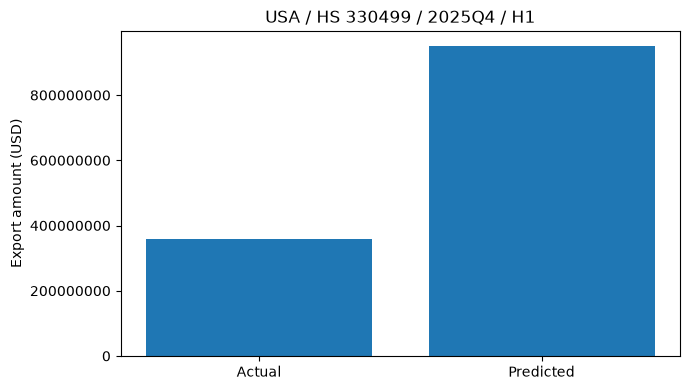

In [2]:
# ===== 여기만 바꾸면 됩니다 =====
COUNTRY = "USA"          # 예: "USA", "JPN" (실제 데이터에 있는 코드)
HS_CODE = "330499"       # HS 제품군 코드 (문자열)
TARGET_QUARTER = "2025Q4"  # 예측 대상 분기
HORIZON = 1             # 1=1분기 전, 2=2분기 전 ...
MODEL = None            # None=최저 WAPE 모델 자동 선택, 또는 "l2_no_macro" 등
# ================================

models = sorted(pred["model_variant"].dropna().unique().tolist())
best_model = (str(summary.sort_values("WAPE_pct").iloc[0]["model_variant"])
              if summary is not None and {"model_variant", "WAPE_pct"}.issubset(summary.columns)
              else models[0])
if best_model not in models:
    best_model = models[0]
model = best_model if MODEL is None else str(MODEL)

print("사용 가능한 모델:", models)
print("사용 가능한 국가:", sorted(pred["country_code"].dropna().unique().tolist()))
if model not in models:
    raise ValueError(f"선택한 모델 {model!r}이 없습니다. 위 모델 목록을 확인하세요.")

country_data = pred.loc[(pred["model_variant"] == model) &
                        (pred["country_code"] == str(COUNTRY))]
if country_data.empty:
    raise ValueError("선택한 모델/국가의 데이터가 없습니다. 출력된 국가 목록을 확인하세요.")
print(f"{COUNTRY}에서 선택 가능한 HS:", sorted(country_data["hs_code"].unique().tolist()))
product_data = country_data.loc[country_data["hs_code"] == str(HS_CODE)]
if product_data.empty:
    raise ValueError("선택한 국가/HS 조합이 없습니다. 위 HS 목록을 확인하세요.")
print("선택 가능한 대상 분기:", sorted(product_data["target_quarter"].unique().tolist()))
quarter_data = product_data.loc[product_data["target_quarter"] == str(TARGET_QUARTER)]
if not quarter_data.empty:
    print("선택 분기의 예측 거리:", sorted(quarter_data["horizon_quarters"].unique().tolist()))

selected = quarter_data.loc[quarter_data["horizon_quarters"] == int(HORIZON)].copy()
if selected.empty:
    raise ValueError("해당 모델·국가·제품군·분기·예측 거리 조합의 결과가 없습니다. 위 선택지를 확인하세요.")

selected["abs_error_usd"] = (selected["actual_usd"] - selected["predicted_usd"]).abs()
selected["error_pct"] = np.where(selected["actual_usd"].abs() > 0,
                                  selected["abs_error_usd"] / selected["actual_usd"].abs() * 100,
                                  np.nan)
selection = {"model": model, "country": str(COUNTRY), "hs": str(HS_CODE),
             "quarter": str(TARGET_QUARTER), "horizon": int(HORIZON)}
print("\n선택 조건:", selection)
display(selected[["origin_quarter", "target_quarter", "actual_usd",
                  "predicted_usd", "abs_error_usd", "error_pct"]].round(2))

actual = selected["actual_usd"].sum()
forecast = selected["predicted_usd"].sum()
den = selected["actual_usd"].abs().sum()
wape = 100 * selected["abs_error_usd"].sum() / den if den else np.nan
print(f"실제 수출액: ${actual:,.0f} | 예측 수출액: ${forecast:,.0f} | 선택 조합 WAPE: {wape:.2f}%")
if len(selected) != 1:
    print(f"참고: 동일 선택 조건에 {len(selected)}개 행이 있어 합계와 개별 행을 함께 표시했습니다.")

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(["Actual", "Predicted"], [actual, forecast])
ax.set_ylabel("Export amount (USD)")
ax.set_title(f"{COUNTRY} / HS {HS_CODE} / {TARGET_QUARTER} / H{HORIZON}")
ax.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()

## STEP 3. 선택한 국가·제품군의 분기별 예측 흐름

STEP 2에서 변수 선택 후 셀을 실행했다면, 같은 모델·국가·HS·예측 거리로 분기별 실제값과 예측값을 비교합니다. 다른 조건을 보고 싶으면 STEP 2의 변수만 바꿔 다시 실행하고 이 셀도 다시 실행하세요.

국가 USA / HS 330499 / l2_no_macro / H1
분기별 전체 WAPE: 69.35% (총 16개 대상 분기)


,target_quarter,actual_usd,predicted_usd,abs_error_usd,error_pct
0,2022Q1,131591550.0,134611460.0,3019910.0,2.29
1,2022Q2,143920715.0,143187440.0,733275.0,0.51
2,2022Q3,124333783.0,144575600.0,20241817.0,16.28
3,2022Q4,120254018.0,137961860.0,17707842.0,14.73
4,2023Q1,152281820.0,138889010.0,13392810.0,8.79
5,2023Q2,191451269.0,146114400.0,45336869.0,23.68
6,2023Q3,228609634.0,143271170.0,85338464.0,37.33
7,2023Q4,230094695.0,137409260.0,92685435.0,40.28
8,2024Q1,257355162.0,144128110.0,113227052.0,44.00
9,2024Q2,346162365.0,147105650.0,199056715.0,57.50


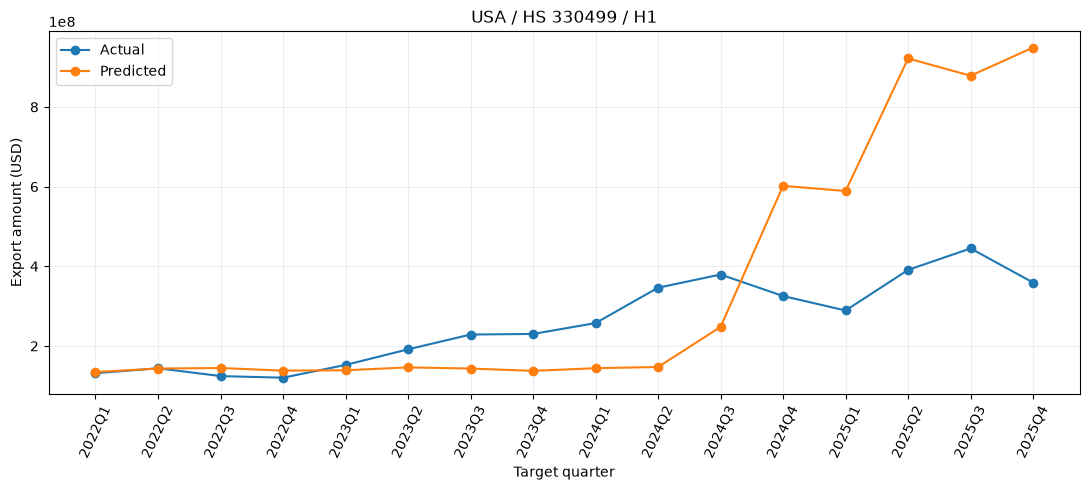

In [3]:
if not selection:
    raise RuntimeError("STEP 2에서 조건을 설정하고 셀을 먼저 실행하세요.")
trend = pred.loc[
    (pred.model_variant == selection["model"]) &
    (pred.country_code == selection["country"]) &
    (pred.hs_code == selection["hs"]) &
    (pred.horizon_quarters == selection["horizon"])
].copy()
trend = (trend.groupby("target_quarter", as_index=False)
         .agg(actual_usd=("actual_usd", "sum"), predicted_usd=("predicted_usd", "sum"))
         .sort_values("target_quarter"))
trend["abs_error_usd"] = (trend.actual_usd - trend.predicted_usd).abs()
trend["error_pct"] = np.where(trend.actual_usd.abs() > 0,
                               trend.abs_error_usd / trend.actual_usd.abs() * 100,
                               np.nan)
den = trend.actual_usd.abs().sum()
trend_wape = 100 * trend.abs_error_usd.sum() / den if den else np.nan
print(f"국가 {selection['country']} / HS {selection['hs']} / {selection['model']} / H{selection['horizon']}")
print(f"분기별 전체 WAPE: {trend_wape:.2f}% (총 {len(trend)}개 대상 분기)")
display(trend.round(2))
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(trend.target_quarter, trend.actual_usd, marker="o", label="Actual")
ax.plot(trend.target_quarter, trend.predicted_usd, marker="o", label="Predicted")
ax.set_ylabel("Export amount (USD)")
ax.set_xlabel("Target quarter")
ax.set_title(f"{selection['country']} / HS {selection['hs']} / H{selection['horizon']}")
ax.tick_params(axis="x", rotation=65)
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## STEP 4. 잘 맞는 조합 vs 오차가 큰 조합 자동 비교

전체 모델 중 검증 WAPE가 가장 낮은 모델을 기준으로, **같은 국가·HS 제품군·예측 거리별** WAPE를 비교합니다. 작은 실제 수출액 때문에 지표가 왜곡되는 경우를 줄이기 위해 `MIN_ACTUAL_USD` 이상인 그룹만 표시합니다. 이 비교는 **검증 결과를 설명하기 위한 사후 분석**으로, 잘 맞는 사례만 골라 일반적인 모델 성능이라고 주장하면 안 됩니다.

In [4]:
MIN_ACTUAL_USD = 1_000_000  # 그룹별 검증 실제 수출액 합계 최소값(USD)
MIN_ROWS = 4  # 적어도 4개 분기 이상의 검증 예측이 있는 조합만
model = best_model
sub = pred.loc[pred.model_variant == model].copy()
sub["abs_error"] = (sub.actual_usd - sub.predicted_usd).abs()
rank = (sub.groupby(["country_code", "hs_code", "horizon_quarters"], as_index=False)
        .agg(rows=("actual_usd", "size"), actual_total=("actual_usd", "sum"),
             absolute_actual_total=("actual_usd", lambda x: x.abs().sum()),
             absolute_error_total=("abs_error", "sum")))
rank = rank[(rank.rows >= MIN_ROWS) & (rank.absolute_actual_total >= MIN_ACTUAL_USD)].copy()
rank["WAPE_pct"] = 100 * rank.absolute_error_total / rank.absolute_actual_total
rank = rank.sort_values("WAPE_pct")
print("비교 모델:", model, "| 조건 통과 조합:", len(rank))
print("\n상대적으로 잘 맞는 조합 10개")
display(rank.head(10)[["country_code", "hs_code", "horizon_quarters", "rows", "actual_total", "WAPE_pct"]].round(2))
print("\n오차가 큰 조합 10개")
display(rank.tail(10).sort_values("WAPE_pct", ascending=False)[["country_code", "hs_code", "horizon_quarters", "rows", "actual_total", "WAPE_pct"]].round(2))

비교 모델: l2_no_macro | 조건 통과 조합: 585

상대적으로 잘 맞는 조합 10개


,country_code,hs_code,horizon_quarters,rows,actual_total,WAPE_pct
595,SGP,330499,1,16,3.607118e+08,7.63
596,SGP,330499,2,16,3.607118e+08,8.89
597,SGP,330499,3,16,3.607118e+08,9.01
496,JPN,330499,2,16,2.408501e+09,10.84
598,SGP,330499,4,16,3.607118e+08,10.95
495,JPN,330499,1,16,2.408501e+09,11.04
497,JPN,330499,3,16,2.408501e+09,11.34
485,JPN,330420,1,16,1.746950e+08,11.83
499,JPN,330499,5,16,2.408501e+09,12.56
685,USA,330590,1,16,1.944306e+08,13.18



오차가 큰 조합 10개


,country_code,hs_code,horizon_quarters,rows,actual_total,WAPE_pct
655,USA,330300,1,16,26019641.0,1084.41
656,USA,330300,2,16,26019641.0,977.58
657,USA,330300,3,16,26019641.0,906.20
658,USA,330300,4,16,26019641.0,824.20
659,USA,330300,5,16,26019641.0,758.79
339,GTM,330499,5,16,2219299.0,366.30
338,GTM,330499,4,16,2219299.0,287.14
337,GTM,330499,3,16,2219299.0,229.00
336,GTM,330499,2,16,2219299.0,160.15
299,GBR,330491,5,16,5977919.0,132.12
